<a href="https://colab.research.google.com/github/Rafael-Labarrere/Machine-Learning/blob/Risco-De-Cr%C3%A9dito/1_1_Inconsistentes_e_Faltantes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pré processamento de dados

# Importação das bibliotecas básicas

In [36]:
import pandas as pd
import random

### Exploração dos dados

In [38]:
# from google.colab import files
# uploaded = files.upload()

In [ ]:
# Importar dataset
base_credit = pd.read_csv('data/credit_data.csv')

In [40]:
#Exibir dataset
base_credit

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
...,...,...,...,...,...
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0


In [41]:
#Exibir as 10 primeiras linhas do dataset
base_credit.head(10)

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
5,6,24904.064140,57.471607,15.498598,0
6,7,48430.359613,26.809132,5722.581981,0
7,8,24500.141984,32.897548,2971.003310,1
8,9,40654.892537,55.496853,4755.825280,0
9,10,25075.872771,39.776378,1409.230371,0


In [42]:
#Exibit as 10 últimas linhas do dataset
base_credit.tail(10)

,clientid,income,age,loan,default
1990,1991,34237.575419,34.101654,2658.090632,0
1991,1992,26300.446554,45.539385,2317.393678,0
1992,1993,30803.806165,23.250084,623.024153,0
1993,1994,54421.410155,26.821928,3273.631823,0
1994,1995,24254.700791,37.751622,2225.284643,0
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0
1999,2000,69436.579552,56.152617,7378.833599,0


In [43]:
#Descrição dos dados
base_credit.describe()

,clientid,income,age,loan,default
count,2000.000000,2000.000000,1997.000000,2000.000000,2000.000000
mean,1000.500000,45331.600018,40.807559,4444.369695,0.141500
std,577.494589,14326.327119,13.624469,3045.410024,0.348624
min,1.000000,20014.489470,-52.423280,1.377630,0.000000
25%,500.750000,32796.459717,28.990415,1939.708847,0.000000
50%,1000.500000,45789.117313,41.317159,3974.719419,0.000000
75%,1500.250000,57791.281668,52.587040,6432.410625,0.000000
max,2000.000000,69995.685578,63.971796,13766.051239,1.000000


In [44]:
#Informações dos dados
base_credit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   clientid  2000 non-null   int64  
 1   income    2000 non-null   float64
 2   age       1997 non-null   float64
 3   loan      2000 non-null   float64
 4   default   2000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 78.3 KB


### Tratamento de valores inconsistentes

In [45]:
base_credit.default.value_counts()

,count
default,
0,1717
1,283


In [46]:
#Pegar os valores menores que zero na coluna de idades
base_credit.loc[base_credit['age'] < 0]

,clientid,income,age,loan,default
15,16,50501.726689,-28.218361,3977.287432,0
21,22,32197.620701,-52.423280,4244.057136,0
26,27,63287.038908,-36.496976,9595.286289,0


In [47]:
# Apagar a coluna inteira (de todos os registros da base de dados)

base_credit2 = base_credit.drop(base_credit[base_credit['age'] < 0].index)
base_credit2

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
...,...,...,...,...,...
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0


In [48]:
# Checar o indice
base_credit.index

RangeIndex(start=0, stop=2000, step=1)

In [49]:
#Checar o indice mediante condicional de idade

base_credit2[base_credit['age'] < 0].index

/tmp/ipykernel_563/368506089.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  base_credit2[base_credit['age'] < 0].index


Index([], dtype='int64')

In [50]:
# Apagar somente os registros com valores inconsistentes
base_credit3 = base_credit.drop(base_credit[base_credit['age'] < 0].index)
base_credit3

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
...,...,...,...,...,...
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0


In [51]:
base_credit3['age'].mean()

np.float64(40.92770044906149)

In [52]:
# Vamos averiguar se foi excluído
base_credit3.loc[base_credit3['age']<0]

,clientid,income,age,loan,default


In [53]:
# calcular a media da base de dados
base_credit2.mean()

,0
clientid,1001.970456
income,45326.596720
age,40.927700
loan,4442.124566
default,0.141713


In [54]:
# Calcular a media de uma coluna na base de dados
base_credit['age'].mean()

np.float64(40.80755937840458)

In [55]:
# Calcular a media da coluna onde os numeros são maiores que zero
base_credit2['age'][base_credit['age'] > 0].mean()

np.float64(40.92770044906149)

In [56]:
# Atribuir a media a coluna
base_credit.loc[base_credit['age'] < 0, 'age'] = 40.92

In [57]:
base_credit2.loc[base_credit['age'] < 19, 'default'] = 1
base_credit2.loc[base_credit['age'] < 19]

,clientid,income,age,loan,default
4,5,66952.688845,18.584336,8770.099235,1
38,39,60921.063104,18.840526,968.836383,1
45,46,41725.612856,18.130038,1185.214700,1
124,125,61952.906689,18.477425,3635.600589,1
243,244,28648.676751,18.396970,1870.925253,1
353,354,46706.458861,18.830336,7084.263509,1
402,403,58079.156901,18.663027,11540.045812,1
412,413,43509.757756,18.075336,7363.037639,1
427,428,55601.271852,18.842993,10533.455162,1
453,454,42522.575757,18.326122,5036.255280,1


### Tratamento de valores faltantes

In [58]:
# checar se há valores nulos
base_credit.isnull()
base_credit.isna()

,clientid,income,age,loan,default
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
1995,False,False,False,False,False
1996,False,False,False,False,False
1997,False,False,False,False,False
1998,False,False,False,False,False


In [59]:
# Somar a quantidade de valores nulos
base_credit.isnull().sum()

,0
clientid,0
income,0
age,3
loan,0
default,0


In [60]:
# Pegar a coluna da idade nas linhas onde tem valores nulos
base_credit.loc[pd.isnull(base_credit['age'])]

,clientid,income,age,loan,default
28,29,59417.805406,NaN,2082.625938,0
30,31,48528.852796,NaN,6155.784670,0
31,32,23526.302555,NaN,2862.010139,0


In [61]:
# Preencher as linhas com as medias das idades
base_credit['age'].fillna(base_credit['age'].mean(), inplace = True)

/tmp/ipykernel_563/3814678194.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  base_credit['age'].fillna(base_credit['age'].mean(), inplace = True)


In [62]:
# Verificar se há valores nulos
base_credit.loc[pd.isnull(base_credit['age'])]

,clientid,income,age,loan,default


In [63]:
base = base_credit.loc[:, 'age'].values

In [64]:
type(base)

numpy.ndarray

In [65]:
# Verificar pelos valores contidos

In [66]:
import numpy as np

In [67]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
imputer.fit(base_credit.iloc[:, 1:3])


SimpleImputer()

In [68]:
base_credit.iloc[:, 1:3] = imputer.transform(base_credit.iloc[:, 1:3])

### Problema de Distribuição

In [69]:
import random
random.seed(32)

In [ ]:
# Importar dataset
base_credit = pd.read_csv('data/credit_data.csv')

In [72]:
ran_int = random.sample(range(0,len(base_credit)),200)

In [73]:
import numpy as np

In [74]:
base_credit.loc[ran_int,'age'] = np.nan

In [75]:
base_credit[base_credit['age'] <= 0] = np.nan

<Axes: xlabel='age', ylabel='Count'>

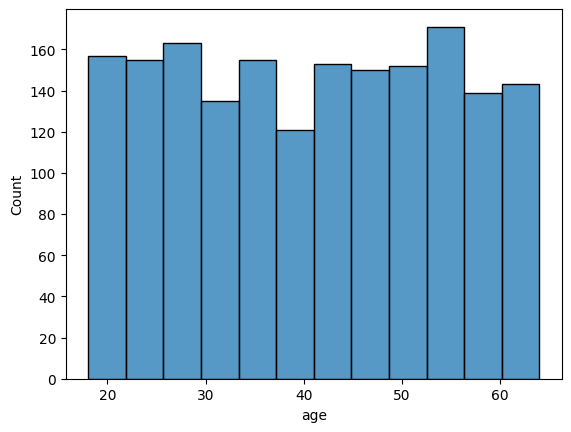

In [76]:
import seaborn as sns
sns.histplot(data = base_credit, x = 'age')

In [77]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
imputer.fit(base_credit.loc[:, ['age']])
base_credit.loc[:, ['age']] = imputer.transform(base_credit.loc[:, ['age']])

<Axes: xlabel='age', ylabel='Count'>

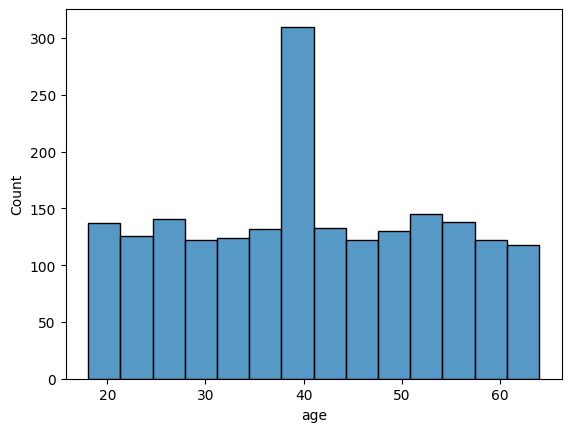

In [78]:
sns.histplot(data = base_credit, x = 'age')